In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# Contract paths — how many requirements until the model picks what the user wants?

The user wants one specific laptop, the **target**: **Dell 14" 8GB**. All three of its features
disagree with the model's default favourite (Apple 16" 16GB). The user can state 0, 1, 2 or 3 of
them. The 8 subsets of {brand, screen, RAM} give **6 paths** from no requirement to the full spec
(one per order of adding them).

- **x** = number of requirements stated (k = 0 … 3).
- **y** = the target's **rank among the 45 laptops** (1 = the model's top pick), from the
  position-corrected Borda score (mean D against the 44 others).

Arguments in the next cell: the model and the target. Runs: `laptops_robustness`, `shopping` frame.

In [2]:
MODEL = ("qwen", "32")
TARGET = {"brand": "Dell", "screen": "14-inch", "ram": "8GB"}

In [3]:
import json
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5d1",
    "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "savefig.bbox": "tight", "savefig.dpi": 200,
})
FIGDIR = "figs/contract_path"
os.makedirs(FIGDIR, exist_ok=True)
BRANDS = ["ASUS", "Apple", "Dell", "HP", "Lenovo"]
FEATS = ["brand", "screen", "ram"]
LAPTOPS = [(b, s, r) for b in BRANDS for s in ["13-inch", "14-inch", "16-inch"] for r in ["4GB", "8GB", "16GB"]]
IDX = {l: i for i, l in enumerate(LAPTOPS)}
TGT = tuple(TARGET[f] for f in FEATS)
SUBSETS = [frozenset(c) for k in range(4) for c in itertools.combinations(FEATS, k)]


def name(sub):
    """{'brand','screen'} -> 'Dell + 14"' ; {} -> 'default'."""
    if not sub:
        return "default"
    return " + ".join(TARGET[f].replace("-inch", '"') for f in FEATS if f in sub)


def short(l):
    return f"{l[0]} {l[1].replace('-inch', '\"')} {l[2]}"


def tensors(d):
    T_ = sorted(d.template_idx.unique())
    M = np.full((len(T_), 45, 45), np.nan)
    ia = [IDX[(a, b, c)] for a, b, c in zip(d.a_brand, d.a_screen, d.a_ram)]
    ib = [IDX[(a, b, c)] for a, b, c in zip(d.b_brand, d.b_screen, d.b_ram)]
    M[[T_.index(t) for t in d.template_idx], ia, ib] = d.score_a.values - d.score_b.values
    return M


RUN, CFG = {}, {}
for r in sorted(os.listdir("data/laptops_robustness")):
    cf, sc = f"data/laptops_robustness/{r}/config.json", f"data/laptops_robustness/{r}/scores.csv"
    if not (os.path.isfile(cf) and os.path.isfile(sc)):
        continue
    c = json.load(open(cf))
    if (c["model_family"], str(c["model_size"])) != MODEL or c["frame"]["name"] != "shopping":
        continue
    cons = c["constraints"]
    if any(TARGET.get(f) != v for f, v in cons.items()):
        continue                                                   # not on the way to the target
    sub = frozenset(cons)
    assert sub not in RUN, f"two complete runs for {name(sub)}"
    RUN[sub] = pd.read_csv(sc)
    CFG[sub] = c
missing = [name(s) for s in SUBSETS if s not in RUN]
print(f"{len(RUN)} of 8 subsets found" + (f"; missing: {missing}" if missing else ""))

8 of 8 subsets found


## Audit — are the runs complete and comparable?

Every run must have 9900 rows (45 × 44 = 1980 ordered pairs × 5 templates), each (ordered pair,
template) exactly once, the same templates as the default run, and a prompt that carries its
contract. PMI regime is reported (`C` = 0 means PMI off); it does not affect D, Borda or ranks.

In [4]:
def pmi_c(d, tol=0.01, min_sat=0.01):
    if max(d.score_a.max(), d.score_b.max()) <= 1e-9:
        return 0.0
    mA, mB = d.score_a.max(), d.score_b.max()
    sat = min((d.score_a > mA - tol).mean(), (d.score_b > mB - tol).mean())
    return mB - mA if sat >= min_sat else np.nan


base_t = CFG[frozenset()]["templates"]
rows = []
for s in SUBSETS:
    if s not in RUN:
        continue
    d, c = RUN[s], CFG[s]
    key = d[["template_idx", "a_brand", "a_screen", "a_ram", "b_brand", "b_screen", "b_ram"]]
    rows.append({"contract": name(s), "job": c.get("slurm_job_id"), "rows": len(d),
                 "unique (pair, template)": int((~key.duplicated()).sum()),
                 "self-pairs": int(((d.a_brand == d.b_brand) & (d.a_screen == d.b_screen) & (d.a_ram == d.b_ram)).sum()),
                 "NaN": int(d[["score_a", "score_b"]].isna().sum().sum()),
                 "same templates": c["templates"] == base_t, "PMI C": round(pmi_c(d), 2),
                 "prompt prefix": c["prompt_prefix"]})
AUD = pd.DataFrame(rows)
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90)
print(AUD.to_string(index=False))
assert (AUD.rows == 9900).all() and (AUD["unique (pair, template)"] == 9900).all()
assert (AUD["self-pairs"] == 0).all() and (AUD.NaN == 0).all() and AUD["same templates"].all()

        contract      job  rows  unique (pair, template)  self-pairs  NaN  same templates  PMI C                                                                           prompt prefix
         default 68373841  9900                     9900           0    0            True   2.25                                                           I am looking to buy a laptop.
            Dell  1445163  9900                     9900           0    0            True   0.00                                   I am looking to buy a laptop. I prefer a Dell laptop.
             14" 68339919  9900                     9900           0    0            True   2.25                                I am looking to buy a laptop. I prefer a 14-inch screen.
             8GB 68374114  9900                     9900           0    0            True   2.25                                        I am looking to buy a laptop. I prefer 8 GB ram.
      Dell + 14"  1445164  9900                     9900           0    0  

In [5]:
# position-corrected Borda per run, and the target's rank
B, RANK = {}, {}
for s, d in RUN.items():
    M = tensors(d)
    D = (M - M.transpose(0, 2, 1)) / 2
    B[s] = pd.Series(np.nanmean(D.mean(0), axis=1), index=LAPTOPS)
    RANK[s] = B[s].rank(ascending=False, method="min")
PATHS = list(itertools.permutations(FEATS))

## F1 — the target's rank vs the number of requirements

One point per subset (3 at k = 1, 3 at k = 2), labelled with what was asked; the 6 paths are the lines
between them. Next to each point: the model's **top pick** under that contract. Rank 1 = the model
now picks exactly what the user wants.

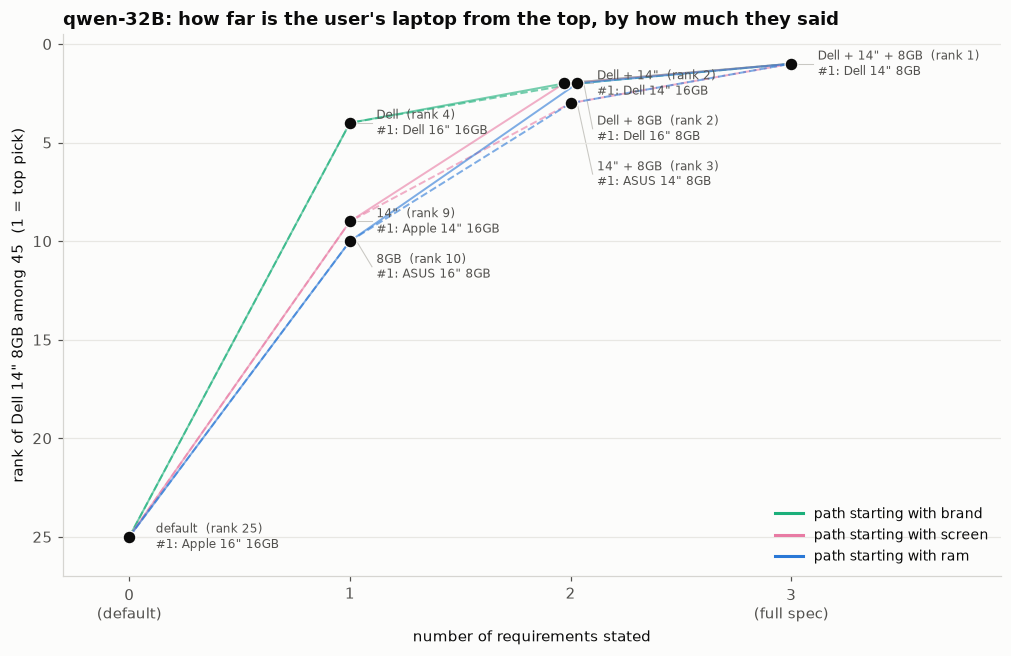

In [6]:
FCOL = {"brand": "#1baf7a", "screen": "#e87ba4", "ram": "#2a78d6"}      # colour = the FIRST feature added on the path
fig, ax = plt.subplots(figsize=(11, 6.4))
ax.grid(True, axis="y", color="#e8e7e3")

# x position of each point: tied points at the same k are nudged apart so both stay visible
XPOS = {}
for k in range(4):
    pts = sorted([s for s in SUBSETS if len(s) == k and s in RANK], key=lambda s: (RANK[s][TGT], name(s)))
    for s in pts:
        same = [t for t in pts if RANK[t][TGT] == RANK[s][TGT]]
        XPOS[s] = k + 0.06 * (same.index(s) - (len(same) - 1) / 2)

for i, p in enumerate(PATHS):
    subs = [frozenset(p[:k]) for k in range(4)]
    if not all(s in RANK for s in subs):
        continue
    ax.plot([XPOS[s] for s in subs], [RANK[s][TGT] for s in subs], color=FCOL[p[0]], lw=1.3, alpha=0.6,
            zorder=2, ls=["-", "--"][i % 2])

for k in range(4):
    pts = sorted([s for s in SUBSETS if len(s) == k and s in RANK], key=lambda s: (RANK[s][TGT], name(s)))
    last = -10
    for s in pts:
        y = RANK[s][TGT]
        ax.scatter(XPOS[s], y, s=70, color=INK, zorder=4, edgecolor=SURFACE, lw=0.8)
        ylab = max(y, last + 2.3)                                    # stack labels at least 2.3 ranks apart
        last = ylab
        ax.plot([XPOS[s] + 0.03, k + 0.1], [y, ylab], color="#c9c8c3", lw=0.7, zorder=1)
        ax.text(k + 0.12, ylab, f"{name(s)}  (rank {int(y)})\n#1: {short(RANK[s].idxmin())}", fontsize=8,
                color=INK_MUTED, va="center")

ax.set_xticks(range(4), ["0\n(default)", "1", "2", "3\n(full spec)"])
ax.set_xlim(-0.3, 3.95)
ax.set_ylim(27, -0.5)
ax.set_xlabel("number of requirements stated")
ax.set_ylabel(f"rank of {short(TGT)} among 45  (1 = top pick)")
hs = [plt.Line2D([], [], color=FCOL[f], lw=2, label=f"path starting with {f}") for f in FEATS]
ax.legend(handles=hs, frameon=False, fontsize=9, loc="lower right")
ax.set_title(f"{MODEL[0]}-{MODEL[1]}B: how far is the user's laptop from the top, by how much they said",
             loc="left", fontweight="bold")
fig.savefig(os.path.join(FIGDIR, f"F1_target_rank_by_k_{MODEL[0]}-{MODEL[1]}B.png"), facecolor=SURFACE)
plt.show()

## F2 — bump charts, one per path

All 45 laptops along each path (rank on y). **Black = the target**, green = the other Dell laptops,
grey = everything else. Six panels = the six orders of adding brand, screen and RAM.

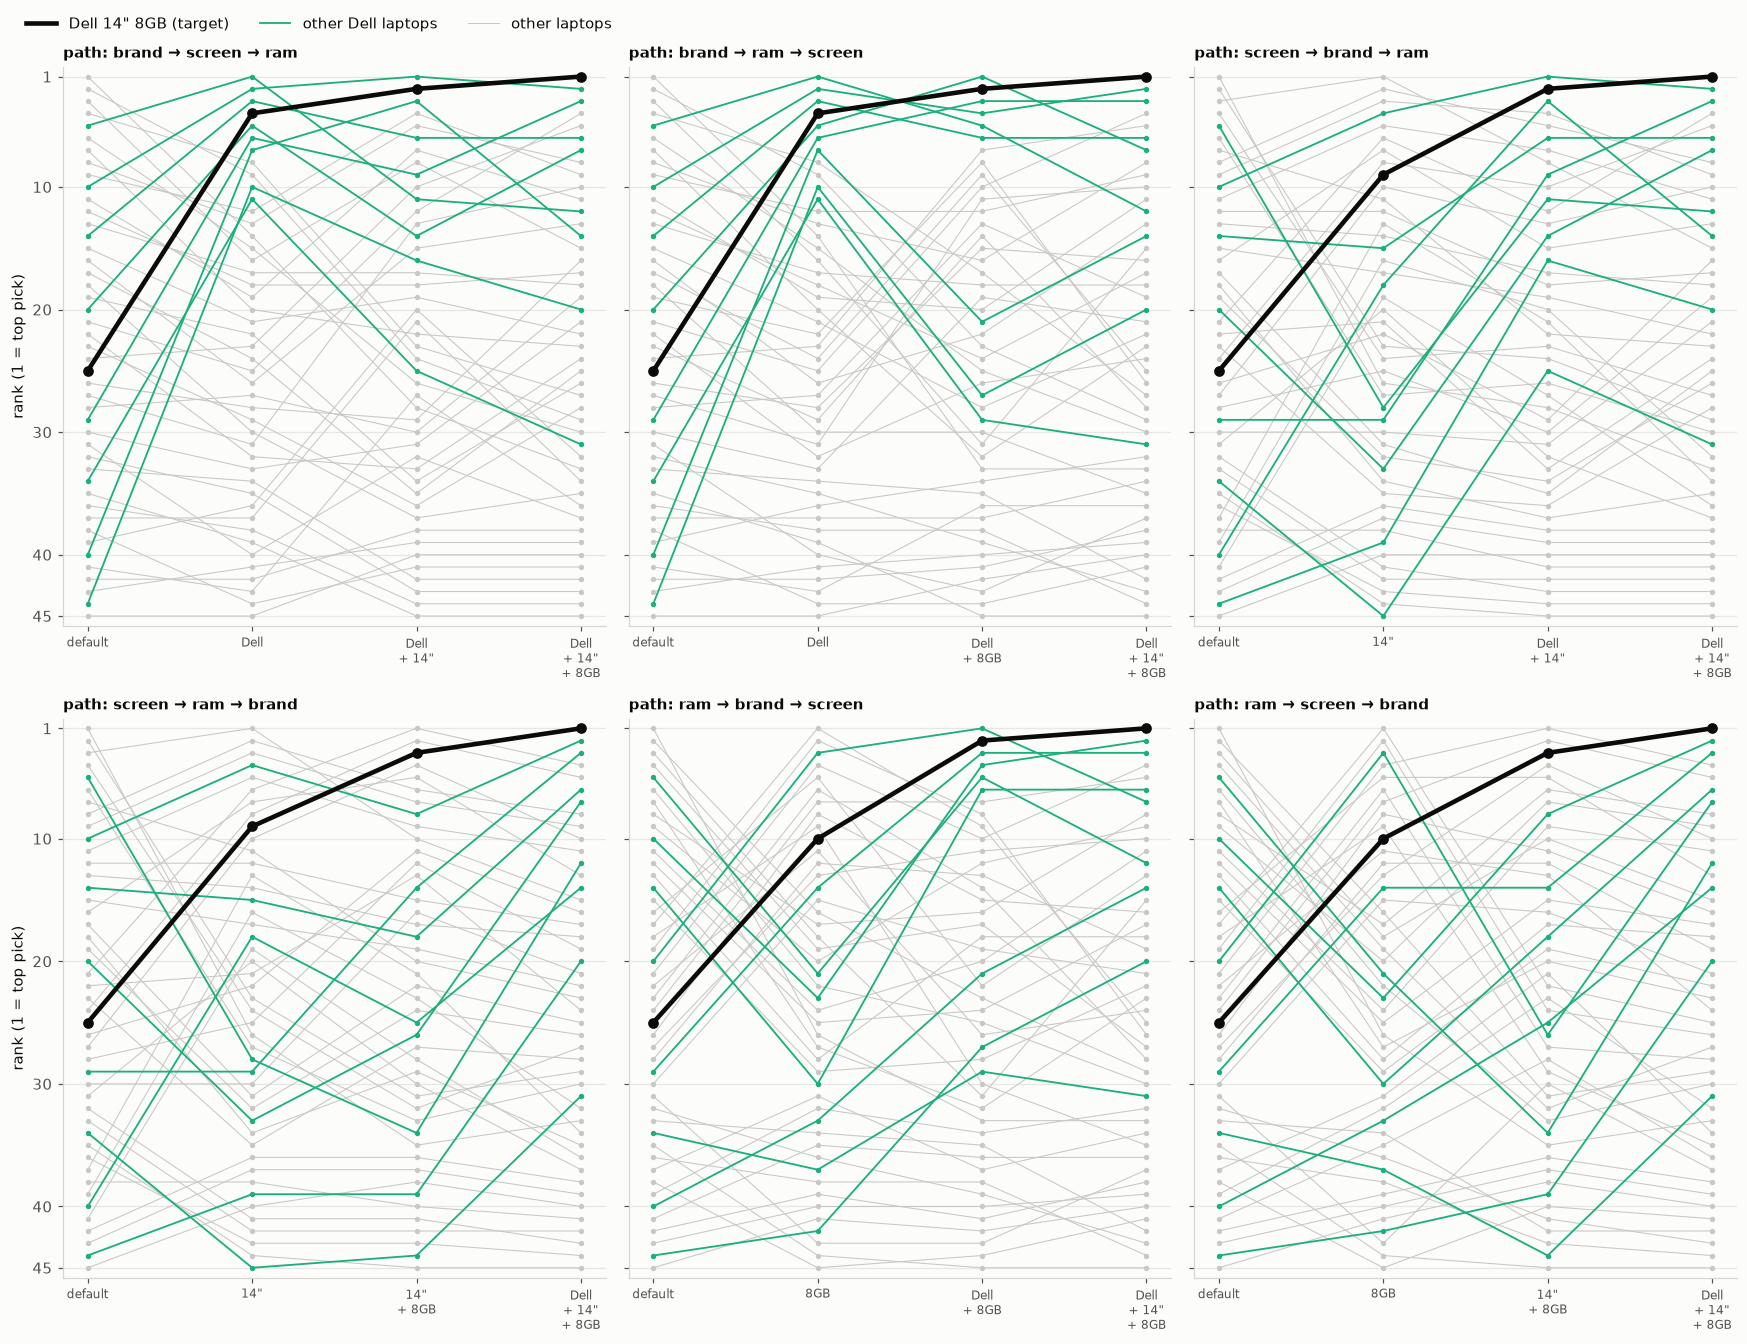

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 12), sharey=True)
for ax, p in zip(axes.flat, PATHS):
    subs = [frozenset(p[:k]) for k in range(4)]
    if not all(s in RANK for s in subs):
        ax.set_visible(False); continue
    for l in LAPTOPS:
        ys = [RANK[s][l] for s in subs]
        tgt, dell = l == TGT, l[0] == "Dell"
        ax.plot(range(4), ys, "-o", ms=2.5 if not tgt else 6, lw=3 if tgt else 1.2 if dell else 0.7,
                color=INK if tgt else "#1baf7a" if dell else "#c9c8c3", zorder=4 if tgt else 3 if dell else 2)
    ax.set_xticks(range(4), [name(s).replace(" + ", "\n+ ") for s in subs], fontsize=8)
    ax.set_ylim(45.8, 0.2)
    ax.set_yticks([1, 10, 20, 30, 40, 45])
    ax.grid(True, axis="y", color="#e8e7e3")
    ax.set_title("path: " + " → ".join(p), loc="left", fontweight="bold", fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("rank (1 = top pick)")
hs = [plt.Line2D([], [], color=INK, lw=3, label=short(TGT) + " (target)"),
      plt.Line2D([], [], color="#1baf7a", lw=1.2, label="other Dell laptops"),
      plt.Line2D([], [], color="#c9c8c3", lw=0.7, label="other laptops")]
fig.legend(handles=hs, loc="upper left", ncol=3, frameon=False, bbox_to_anchor=(0.01, 1.02))
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, f"F2_bump_paths_{MODEL[0]}-{MODEL[1]}B.png"), facecolor=SURFACE)
plt.show()